# Session 31 Solutions: Feature Engineering and Explaining Models

Data Science with Python, Level 2, Stage 4: Applied ML

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score, mean_absolute_error

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
bikes["date"] = pd.to_datetime(bikes["date"])
folds = KFold(n_splits=5, shuffle=True, random_state=0)

linear = LinearRegression()
boost = HistGradientBoostingRegressor(random_state=0)

def cv_r2(model, cols):
    return cross_val_score(model, bikes[cols].astype(float), bikes["rentals"], cv=folds).mean().round(3)

## In-Class Exercises

### In-Class Exercise 1: Weekday Pattern

In [2]:
bikes["day_of_week"] = bikes["date"].dt.dayofweek
print(bikes.groupby("day_of_week")["rentals"].mean().round())
print(bikes.groupby("working_day")["rentals"].mean().round())

day_of_week
0    4185.0
1    4218.0
2    4124.0
3    4157.0
4    4176.0
5    3696.0
6    3520.0
Name: rentals, dtype: float64
working_day
False    3587.0
True     4199.0
Name: rentals, dtype: float64


### In-Class Exercise 2: Month as Category

In [3]:
bikes["year"] = bikes["date"].dt.year - 2023
bikes["month"] = bikes["date"].dt.month
base = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday", "year"]
dummies = pd.get_dummies(bikes["month"], prefix="m", drop_first=True)
d = pd.concat([bikes, dummies], axis=1)
d["m_sin"] = np.sin(2 * np.pi * d["month"] / 12)
d["m_cos"] = np.cos(2 * np.pi * d["month"] / 12)
for name, cols in [("number", base + ["month"]), ("one-hot", base + list(dummies.columns)), ("circle", base + ["m_sin", "m_cos"])]:
    print(name, cross_val_score(LinearRegression(), d[cols].astype(float), d["rentals"], cv=folds).mean().round(3))

number 0.816
one-hot 0.814
circle 0.816


### In-Class Exercise 3: Explain the Linear Model

In [4]:
bikes["year"] = bikes["date"].dt.year - 2023
day = bikes["date"].dt.dayofyear
bikes["doy_sin"] = np.sin(2 * np.pi * day / 365)
bikes["doy_cos"] = np.cos(2 * np.pi * day / 365)
bikes["weekend"] = (bikes["date"].dt.dayofweek >= 5).astype(int)
bikes["bad_weather"] = (bikes["weather"] == "Rain").astype(int)
bikes["temp_sq"] = bikes["temp_c"] ** 2
features = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday", "year", "doy_sin", "doy_cos", "temp_sq", "bad_weather", "weekend"]
X_train, X_test, y_train, y_test = train_test_split(bikes[features].astype(float), bikes["rentals"], test_size=0.25, random_state=0)
lin = LinearRegression().fit(X_train, y_train)
r = permutation_importance(lin, X_test, y_test, n_repeats=10, random_state=0)
pd.Series(r.importances_mean, index=features).sort_values(ascending=False).round(3)

temp_c         1.197
bad_weather    0.289
year           0.129
working_day    0.077
humidity       0.061
temp_sq        0.005
doy_cos        0.005
weekend        0.002
wind_kmh       0.001
holiday       -0.000
doy_sin       -0.001
dtype: float64

### In-Class Exercise 4: Rain and Temperature Together

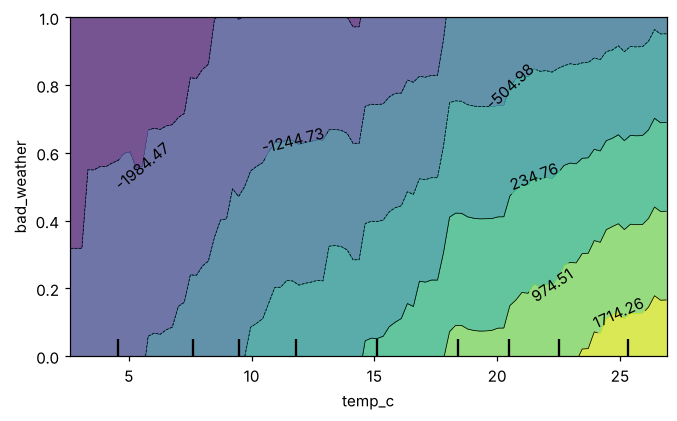

In [5]:
bikes["year"] = bikes["date"].dt.year - 2023
bikes["bad_weather"] = (bikes["weather"] == "Rain").astype(int)
cols = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday", "year", "bad_weather"]
m = HistGradientBoostingRegressor(random_state=0).fit(bikes[cols].astype(float), bikes["rentals"])
PartialDependenceDisplay.from_estimator(m, bikes[cols].astype(float), [("temp_c", "bad_weather")])
plt.show()

## Part A: Basic

### Exercise 1: Date Parts

In [6]:
d = bikes[["date"]].copy()
d["year"] = d["date"].dt.year
d["month"] = d["date"].dt.month
d["day"] = d["date"].dt.day
d["day_of_week"] = d["date"].dt.dayofweek
d["day_name"] = d["date"].dt.day_name()
d.head()

,date,year,month,day,day_of_week,day_name
0,2023-01-01,2023,1,1,6,Sunday
1,2023-01-02,2023,1,2,0,Monday
2,2023-01-03,2023,1,3,1,Tuesday
3,2023-01-04,2023,1,4,2,Wednesday
4,2023-01-05,2023,1,5,3,Thursday


### Exercise 2: Hours on a Circle

In [7]:
h = pd.DataFrame({"hour": range(24)})
h["hour_sin"] = np.sin(2 * np.pi * h["hour"] / 24)
h["hour_cos"] = np.cos(2 * np.pi * h["hour"] / 24)
p = h.set_index("hour")[["hour_sin", "hour_cos"]]
print(round(np.linalg.norm(p.loc[23] - p.loc[0]), 4), round(np.linalg.norm(p.loc[0] - p.loc[1]), 4))

0.2611 0.2611


## Part B: Intermediate

### Exercise 3: Apartment Features

In [8]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
flats["area_per_room"] = flats["area_m2"] / flats["rooms"]
flats["is_new"] = (flats["building_age"] < 5).astype(int)
flats["top_floor"] = (flats["floor"] >= 8).astype(int)
flats["central"] = (flats["distance_center_km"] < 2).astype(int)
orig = ["area_m2", "rooms", "floor", "building_age", "distance_center_km", "elevator", "parking"]
new = orig + ["area_per_room", "is_new", "top_floor", "central"]
for cols in [orig, new]:
    m = HistGradientBoostingRegressor(random_state=0)
    print(len(cols), -cross_val_score(m, flats[cols].astype(float), flats["price_k"], cv=folds, scoring="neg_mean_absolute_error").mean().round(2))

7 11.99
11 11.75


### Exercise 4: Which Apartment Features Matter?

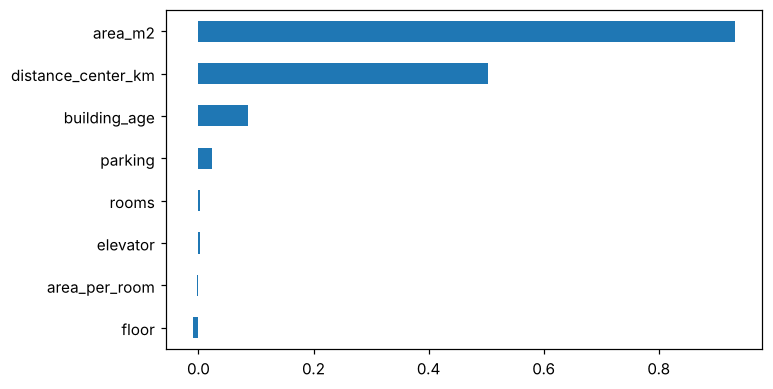

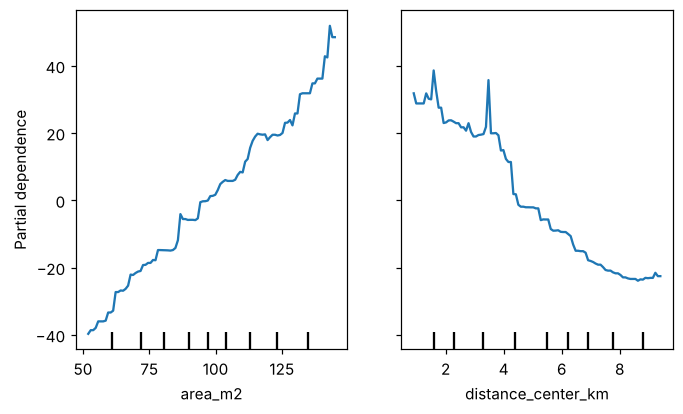

In [9]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
flats["area_per_room"] = flats["area_m2"] / flats["rooms"]
cols = ["area_m2", "rooms", "floor", "building_age", "distance_center_km", "elevator", "parking", "area_per_room"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(flats[cols].astype(float), flats["price_k"], test_size=0.25, random_state=0)
m = HistGradientBoostingRegressor(random_state=0).fit(Xa_train, ya_train)
r = permutation_importance(m, Xa_test, ya_test, n_repeats=10, random_state=0)
pd.Series(r.importances_mean, index=cols).sort_values().plot.barh()
plt.show()
PartialDependenceDisplay.from_estimator(m, Xa_train, ["area_m2", "distance_center_km"])
plt.show()

## Part C: Challenge

### Exercise 5: Last Week's Rentals

Lag features carry the trend into the model, which is why they help when the test year is busier than the training year.

In [10]:
d = bikes.sort_values("date").copy()
d["year"] = d["date"].dt.year
d["rentals_lag1"] = d["rentals"].shift(1)
d["rentals_avg7"] = d["rentals"].shift(1).rolling(7).mean()
d = d.dropna()
train, test = d[d["year"] == 2023], d[d["year"] == 2024]
base = ["temp_c", "humidity", "wind_kmh", "working_day", "holiday"]
for cols in [base, base + ["rentals_lag1", "rentals_avg7"]]:
    m = HistGradientBoostingRegressor(random_state=0).fit(train[cols].astype(float), train["rentals"])
    print(len(cols), round(r2_score(test["rentals"], m.predict(test[cols].astype(float))), 3))
# Without shift(1), the features would contain today's rentals: the answer itself.

5 0.575
7 0.532


## Part D: Cumulative Project: Customer Churn

### Exercise 6: Customer Churn: Step 8, Explain the Model

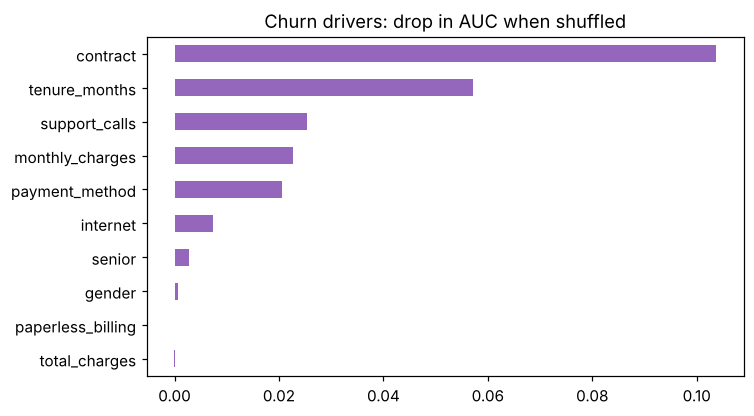

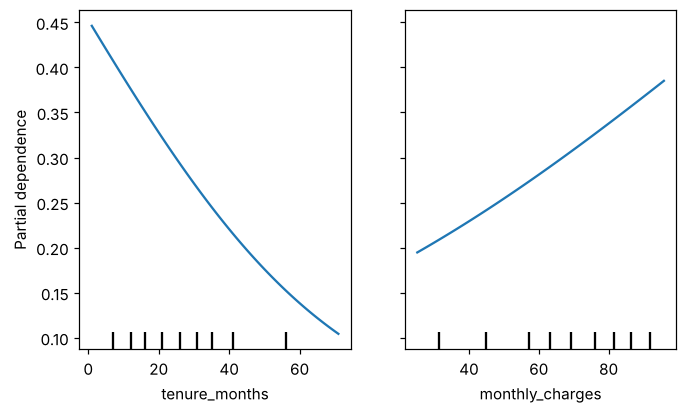

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (churn["churn"] == "Yes").astype(int)
X = churn.drop(columns=["customer_id", "churn"])
X_dev, X_final, y_dev, y_final = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
pipe = Pipeline([("prep", pre), ("model", LogisticRegression(C=1, max_iter=1000))]).fit(X_dev, y_dev)
r = permutation_importance(pipe, X_dev, y_dev, n_repeats=10, random_state=0, scoring="roc_auc")
pd.Series(r.importances_mean, index=X_dev.columns).sort_values().plot.barh(color="tab:purple")
plt.title("Churn drivers: drop in AUC when shuffled")
plt.show()
X_float = X_dev.astype({"tenure_months": float, "support_calls": float})
PartialDependenceDisplay.from_estimator(pipe, X_float, ["tenure_months", "monthly_charges"])
plt.show()

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Cycles wrap around. |
| 2 | B | Shuffling breaks the feature's link with the target. |
| 3 | B | Correlated twins share importance. |
| 4 | B | Other features are averaged over. |
| 5 | C | It is the target itself. |